# TinyStories

In [1]:
from torch import nn

from artifacts.core.artifact import Resources
from artifacts.core.resolve import resolve
from artifacts.core.SGD.training import LoopConfig, LRSchedule, OptimizerParameters, TrainingParameters
from artifacts.mappeddataset import MappedDataSet
from artifacts.sources import SourceURL
from artifacts.stages.pretraining import Pretraining
from artifacts.tokenizers.bpe import Tokenizer as BPETokenizer
from models.transformer import Transformer
from profiling.profile_events import aggregate_kernels, display_steps, events_to_rows, launch_chain
from profiling.step_report import build_report
from profiling.util import run_profile

In [2]:
HF = "https://huggingface.co/datasets/roneneldan/TinyStories/resolve/main"
train = SourceURL(name="tinystories-train", url=f"{HF}/TinyStoriesV2-GPT4-train.txt")
valid = SourceURL(name="tinystories-valid", url=f"{HF}/TinyStoriesV2-GPT4-valid.txt")

tokenizer = BPETokenizer(
    vocab_size=10000,
    special_tokens=("<|endoftext|>",),
    sources=(valid,),
    allocated_resources=Resources(cpu=4),
)

dataset = MappedDataSet.from_sources(
    tokenizer=tokenizer,
    train_sources=(train,),
    valid_sources=(valid,),
)

pretraining = Pretraining(
    run_id="runofex",
    dataset=dataset,
    model=Transformer(
        vocab_size=tokenizer.vocab_size,
        d_model=64,
        d_ff=128,
        sequence_length=32,
        num_layers=4,
        num_heads=16,
        rope_theta=10000,
        dtype="torch.float32",
    ),
    training_parameters=TrainingParameters(
        total_steps=20000,
        batch_size=64,
        max_norm=1.0,
        lr_schedule=LRSchedule(
            max_learning_rate=3e-4,
            min_learning_rate=3e-5,
            warmup_iters=200,
            cosine_cycle_iters=5000,
        ),
        optimizer="torch.optim.AdamW",
        optimizer_parameters=OptimizerParameters(
            lr=3e-4,
            betas=(0.9, 0.95),
            weight_decay=0.1,
            eps=1e-8,
        ),
        seed=0,
    ),
    loop_config=LoopConfig(
        checkpoint_every=5000,
        val_every=200,
        gpu_check_every=200,
    ),
    allocated_resources=Resources(gpu_type="T4", gpu_count=1),
    tags={"experiment": ["myfirstexperiment"]},
)

## Declare

In [3]:
for artifact in resolve(pretraining):
    print(f"{type(artifact).__name__:16} {artifact.artifact_path}")

SourceURL        sources/tinystories-train
SourceURL        sources/tinystories-valid
Tokenizer        tokenizers/bpe-10000-b46983c6f3
TokenizedSource  tokenized/bpe-10000-b46983c6f3/tinystories-train
TokenizedSource  tokenized/bpe-10000-b46983c6f3/tinystories-valid
MappedDataSet    mappeddatasets/mapped-2be543ce28
Pretraining      runs/runofex/pretraining/0-20000-2956000f6f


In [4]:
from local import declare_on_volume
report = declare_on_volume(pretraining, verbose=True, commit=True)  # commit=True publishes

sources/tinystories-train                         done  (drift: 73684a0 -> 5d6b791)
sources/tinystories-valid                         done  (drift: f9752b6 -> 5d6b791)
tokenizers/bpe-10000-b46983c6f3                   done  (drift: f9752b6 -> 5d6b791)
tokenized/bpe-10000-b46983c6f3/tinystories-train  done  (drift: f9752b6 -> 5d6b791)
tokenized/bpe-10000-b46983c6f3/tinystories-valid  done  (drift: f9752b6 -> 5d6b791)
mappeddatasets/mapped-2be543ce28                  done  (drift: f9752b6 -> 5d6b791)
runs/runofex/pretraining/0-20000-2956000f6f       declared

1 declared, 6 done
1 manifest written: runs/runofex/pretraining/0-20000-2956000f6f


## Benchmark

In [14]:
captured = run_profile(
    pretraining.allocated_resources,
    model_declaration=pretraining.model,
    training_parameters=pretraining.training_parameters,
    batch_size=pretraining.training_parameters.batch_size,
    warmup_steps=5,
    profile_steps=4,
    autocast=None,  # PretrainJob trains without autocast
    kernel_events=True,
    module_scopes=True,
    peak_memory=True,
    trace_memory=True,
)

profile call fc-01M5Y1C9EGRF421J99VCYHY51P
INFO profile: Transformer on Tesla T4, batch_size 64
INFO profile: warmup: 5 steps
INFO profile: step 0: 147.8 ms
INFO profile: step 1: 149.3 ms
INFO profile: step 2: 148.0 ms
INFO profile: step 3: 151.0 ms
INFO profile: done


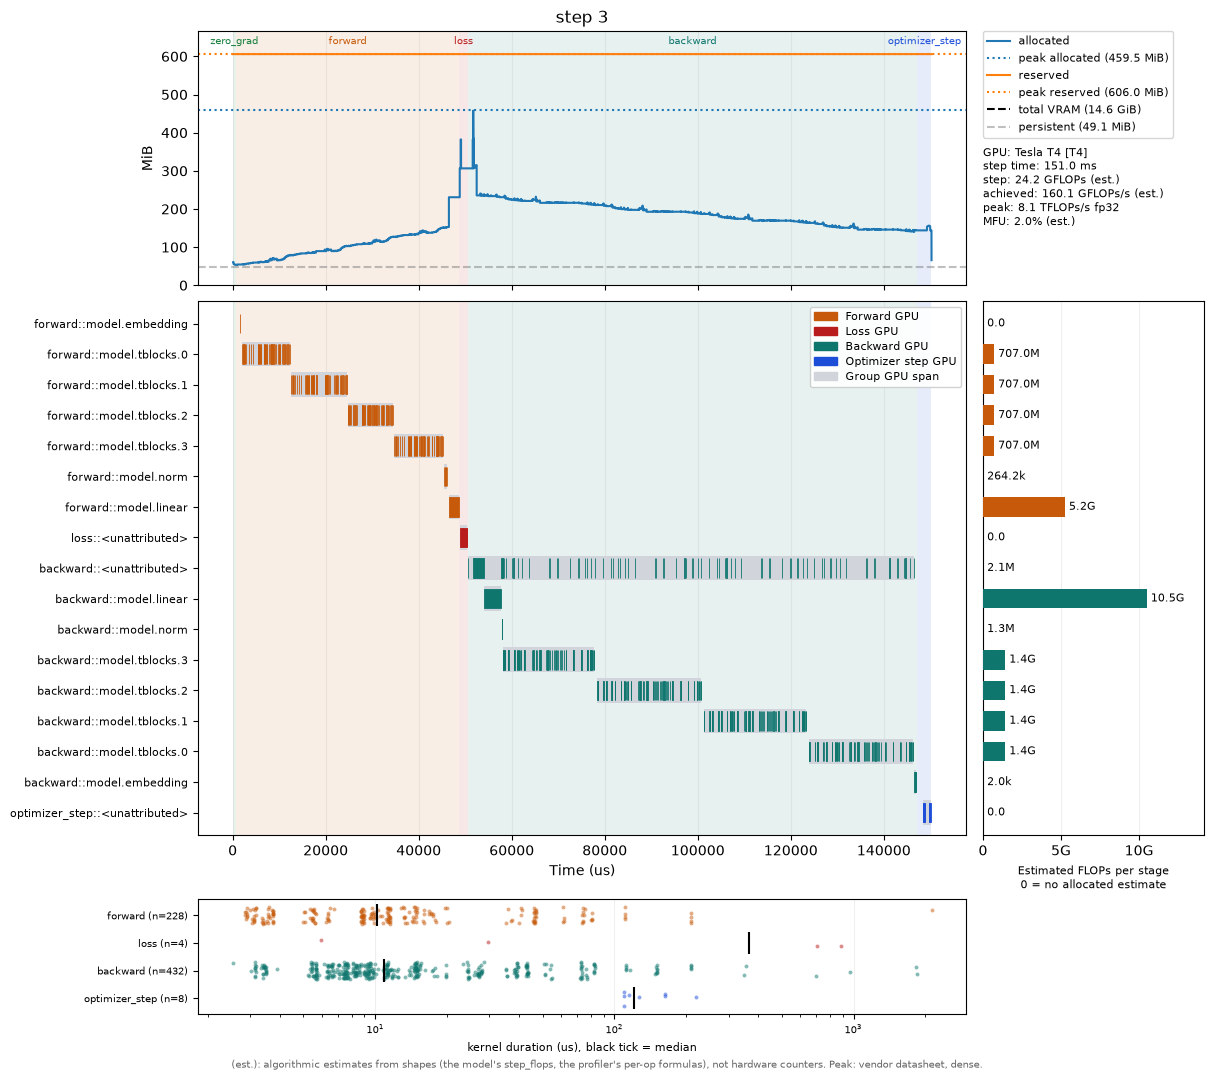

In [17]:
report = build_report(captured, depth=3)
display_steps(report, steps=[3])

In [18]:
step = max(captured["steps"])
rows = events_to_rows(captured["steps"][step]["events"])
groups, kernels, unattributed_kernels, flop_sources = aggregate_kernels(rows, depth=3)
display(groups[["kernel_count", "gpu_time_us", "gpu_span_us", "estimated_flops"]])

kernel_count  gpu_time_us  gpu_span_us  \
phase          module_fqn                                                
forward        model.embedding             1       13.120       13.120   
               model.linear                1     2120.464     2120.464   
               model.norm                  6       51.328      596.371   
               model.tblocks.0            55     1248.291    10398.196   
               model.tblocks.1            55     1244.703    11879.699   
               model.tblocks.2            55     1245.763     9786.755   
               model.tblocks.3            55     1253.765    10489.490   
loss           <unattributed>              4     1625.019     1628.763   
backward       <unattributed>             84     3152.436    95777.732   
               model.embedding             7       85.598      279.418   
               model.linear                2     3659.533     3664.717   
               model.norm                 15      155.740      188.924   
               model.tblocks.0            81     2225.940    22406.084   
               model.tblocks.1            81     2229.067    22052.908   
               model.tblocks.2            81     2229.197    22268.679   
               model.tblocks.3            81     2230.320    19750.432   
optimizer_step <unattributed>              8     1113.158     1796.023   

                                estimated_flops  
phase          module_fqn                        
forward        model.embedding     0.000000e+00  
               model.linear        5.242880e+09  
               model.norm          2.641920e+05  
               model.tblocks.0     7.070075e+08  
               model.tblocks.1     7.070075e+08  
               model.tblocks.2     7.070075e+08  
               model.tblocks.3     7.070075e+08  
loss           <unattributed>      0.000000e+00  
backward       <unattributed>      2.097152e+06  
               model.embedding     2.048000e+03  
               model.linear        1.048576e+10  
               model.norm          1.314816e+06  
               model.tblocks.0     1.416110e+09  
               model.tblocks.1     1.416110e+09  
               model.tblocks.2     1.416110e+09  
               model.tblocks.3     1.416110e+09  
optimizer_step <unattributed>      0.000000e+00

In [19]:
display(kernels[["name", "phase", "module_fqn", "owner_fqn", "gpu_start_us", "duration_us"]])

,name,phase,module_fqn,owner_fqn,gpu_start_us,duration_us
index,,,,,,
14,"void at::native::vectorized_gather_kernel<16, ...",forward,model.embedding,model.embedding,2966.336,13.120
2039,volta_sgemm_128x128_tn,forward,model.linear,model.linear,47889.222,2120.464
1987,void at::native::vectorized_elementwise_kernel...,forward,model.norm,model.norm,46852.541,6.688
1990,"void at::native::reduce_kernel<512, 1, at::nat...",forward,model.norm,model.norm,46965.659,14.944
1993,void at::native::vectorized_elementwise_kernel...,forward,model.norm,model.norm,47069.240,3.168
...,...,...,...,...,...,...
8755,void at::native::(anonymous namespace)::multi_...,optimizer_step,<unattributed>,NaN,150143.383,162.141
8915,void at::native::(anonymous namespace)::multi_...,optimizer_step,<unattributed>,NaN,150978.788,115.230
8919,void at::native::(anonymous namespace)::multi_...,optimizer_step,<unattributed>,NaN,151095.714,126.173


In [13]:
kernel_id = report["steps"][str(step)]["kernels"]["id"][0]
display(launch_chain(rows, kernel_id, format=True))

,name,activity_type,device_type,start_us,end_us,launcher_id,correlation_id,linked_correlation_id,flops,input_shapes,input_dtypes
index,,,,,,,,,,,
5,train::forward,user_annotation,DeviceType.CPU,5420.749,255537.258,<NA>,7683,0,0,[],[]
7,forward::model,user_annotation,DeviceType.CPU,5522.520,253679.856,5,7684,0,0,[],[]
8,forward::model.embedding,user_annotation,DeviceType.CPU,5658.422,6388.264,7,7685,0,0,[],[]
9,aten::index,cpu_op,DeviceType.CPU,5830.263,6176.896,8,7686,0,0,"[[10000, 128], []]","[float, ]"
13,cudaLaunchKernel,cuda_runtime,DeviceType.CPU,6053.240,6167.852,9,15931,7686,0,[],[]
14,"void at::native::vectorized_gather_kernel<16, ...",kernel,DeviceType.CUDA,6159.088,6171.568,13,15931,7686,0,[],[]
